# Dendrogram tryout

In [1]:
import nltk
nltk.download('stopwords')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\tomww\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\tomww\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [2]:
import comparing_and_showing as cs

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\tomww\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [7]:
x = cs.get_aggregated_results("Corpus/TateMcRae_songs", n_sample=50)

------------------------------
Récupération des résultats n°1
vocabulaire Bag Of Words créé
vocabulaire n-grams de mot créé
vocabulaire n-grams de caractères créé
vocabulaire n-grams de phonemes créé
['persona_tatiana' 'persona_tate_baseline']
resultats obtenus pour <scorer_longMoy>
resultats obtenus pour <scorer_divLex_HDD>
resultats obtenus pour <scorer_divLex_MTLD>
resultats obtenus pour <scorer_densLex>
resultats obtenus pour <scorer_bowVec>
resultats obtenus pour <scorer_n_grams_motsVec>
resultats obtenus pour <scorer_n_grams_charVec>
resultats obtenus pour <scorer_n_grams_phonVec>
------------------------------
Récupération des résultats n°2
vocabulaire Bag Of Words créé
vocabulaire n-grams de mot créé
vocabulaire n-grams de caractères créé
vocabulaire n-grams de phonemes créé
['persona_tatiana' 'persona_tate_baseline']
resultats obtenus pour <scorer_longMoy>
resultats obtenus pour <scorer_divLex_HDD>
resultats obtenus pour <scorer_divLex_MTLD>
resultats obtenus pour <scorer_dens

Affichage pour <scorer_longMoy>
Affichage pour <scorer_divLex_HDD>
Affichage pour <scorer_divLex_MTLD>
Affichage pour <scorer_densLex>
Affichage pour <scorer_bowVec>
Affichage pour <scorer_n_grams_motsVec>
Affichage pour <scorer_n_grams_charVec>
Affichage pour <scorer_n_grams_phonVec>


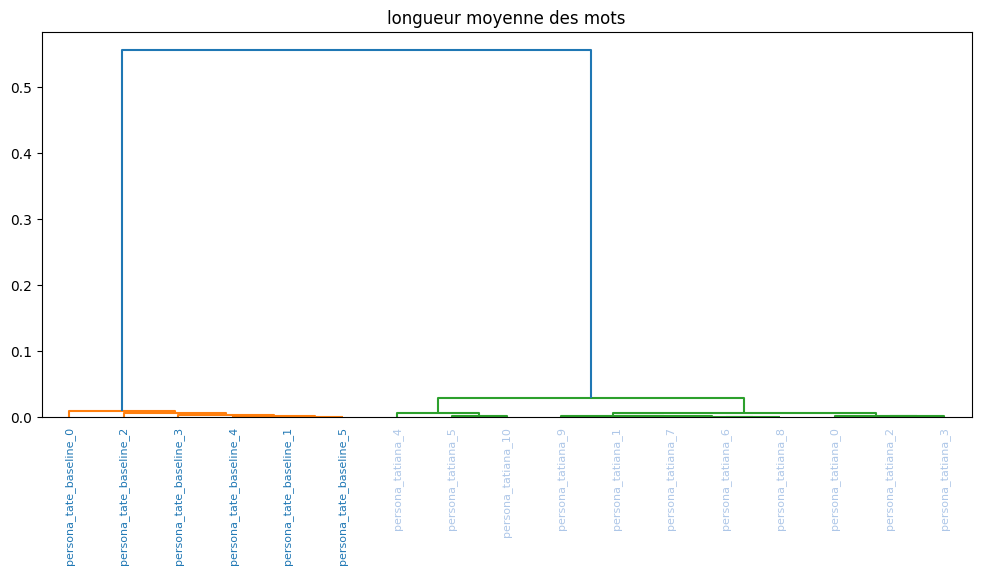

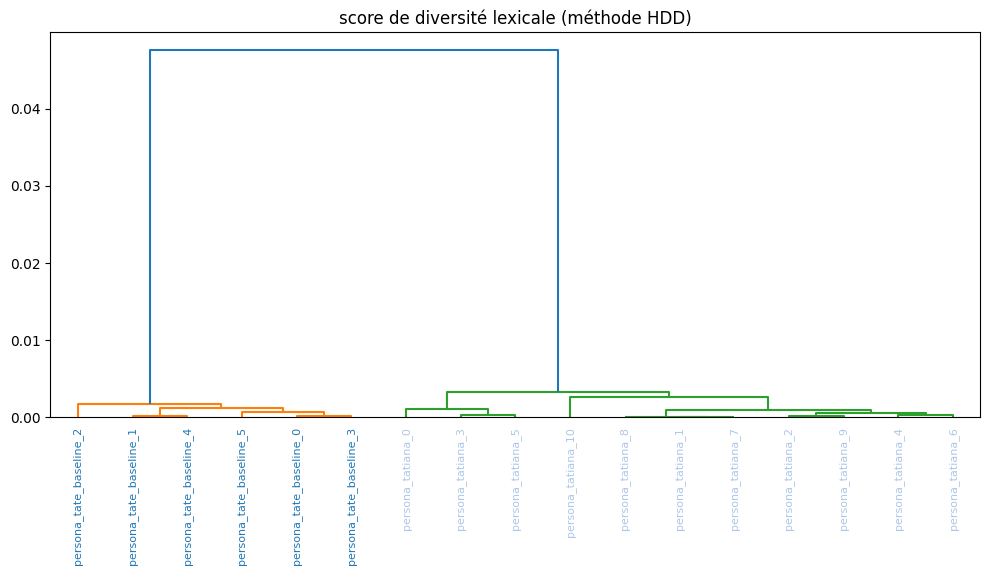

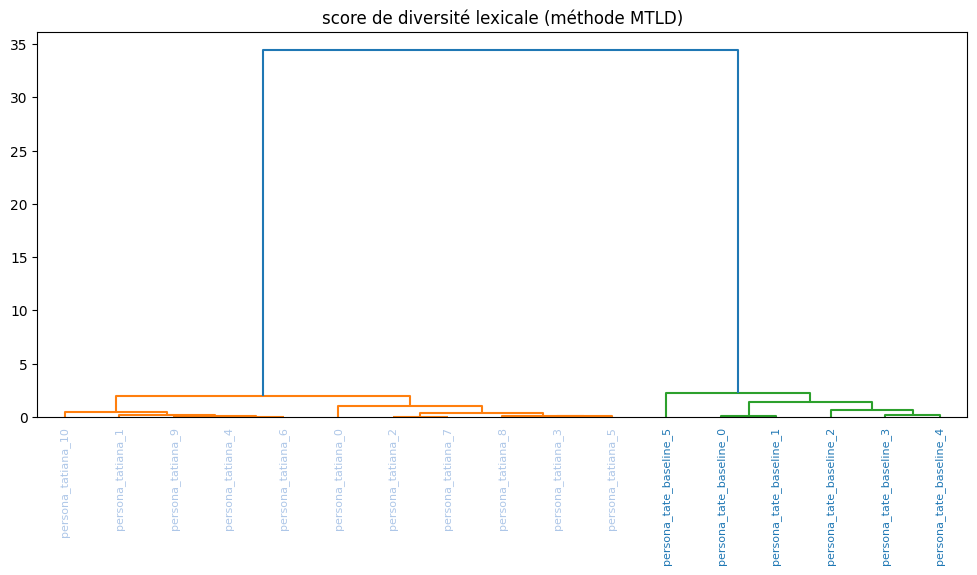

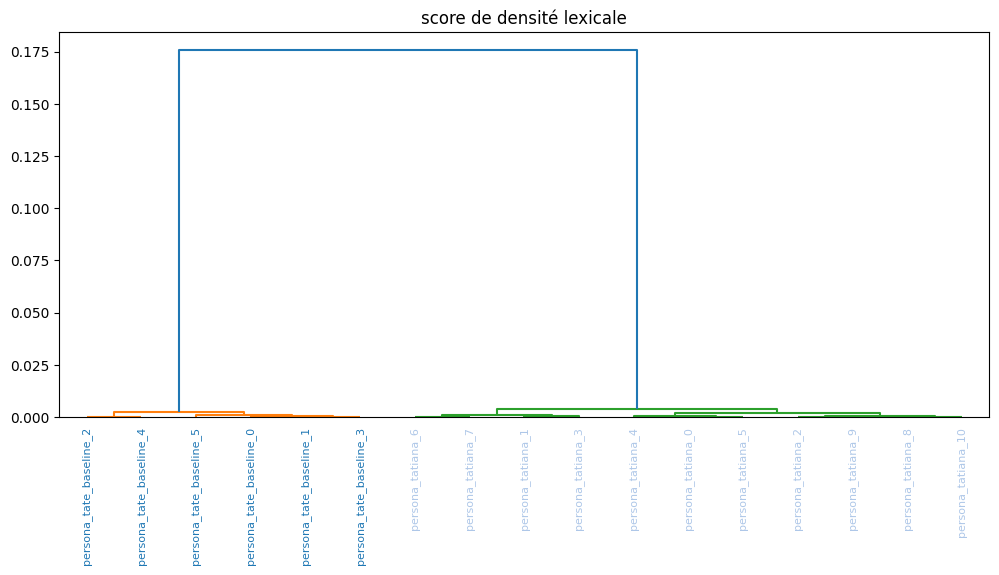

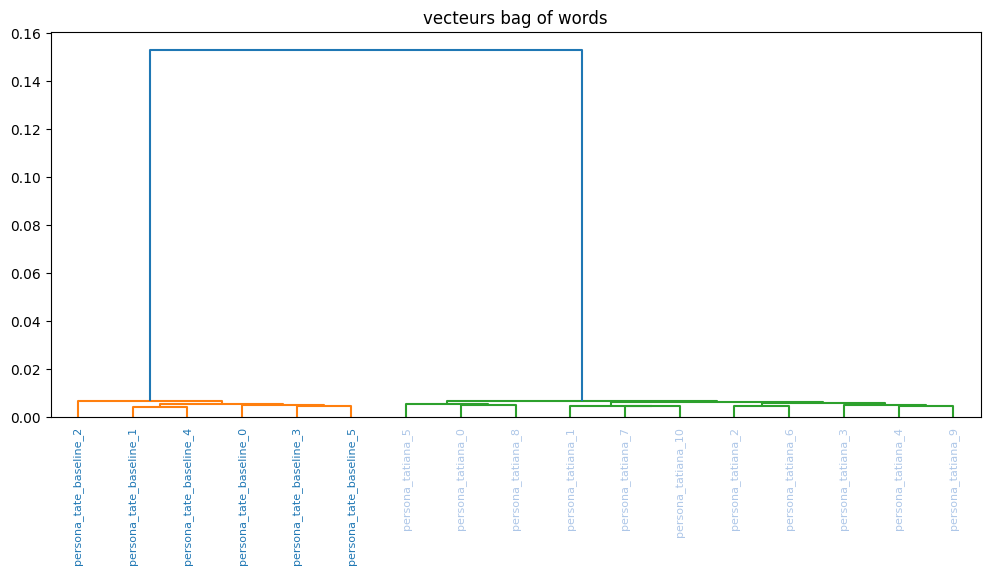

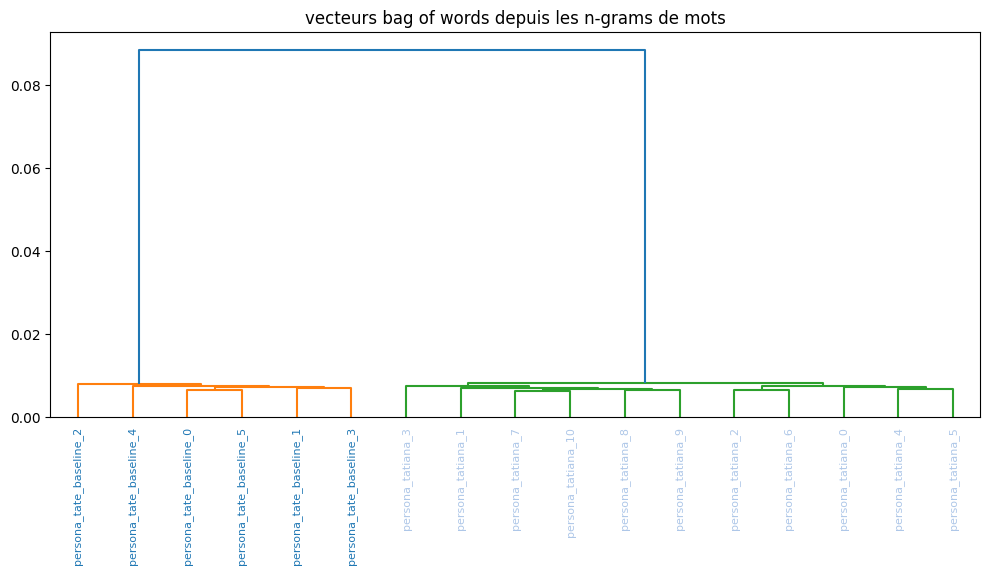

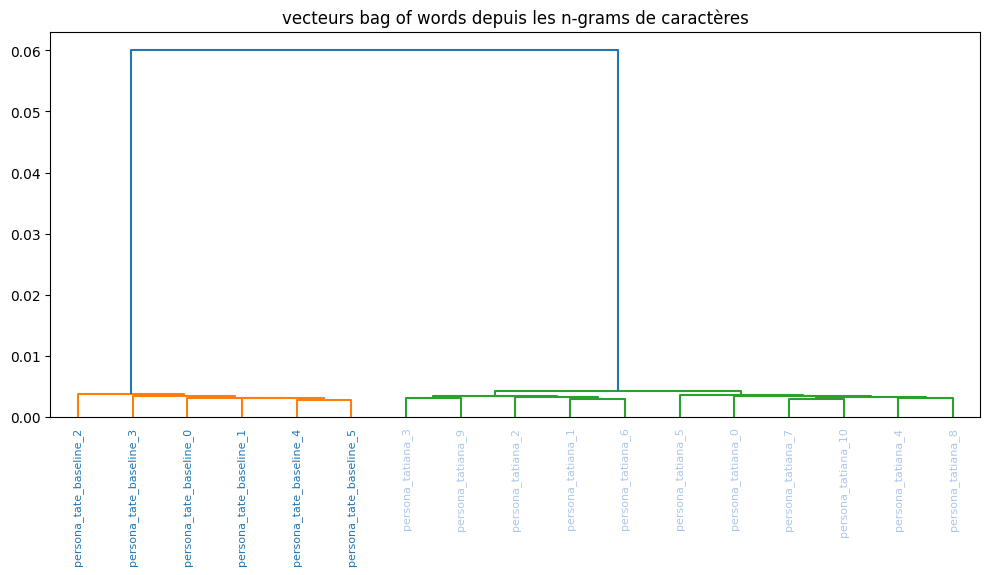

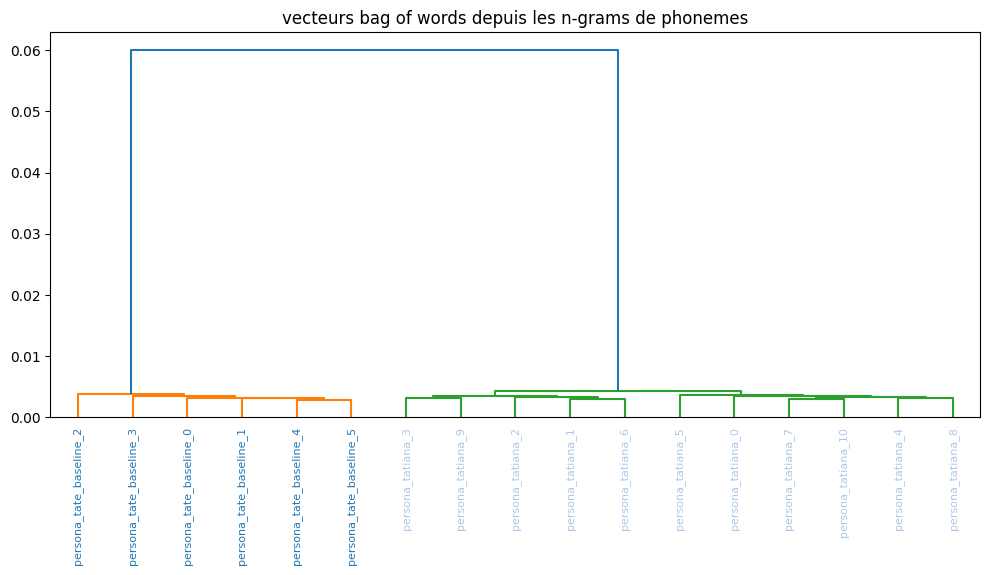

In [8]:
results = x
from score_utils import available_metrics
scorers = available_metrics
labels = list(results[scorers[0].name].keys())
for scorer in scorers : 
    print(f"Affichage pour {scorer}")
    cs.create_dendrogram(results[scorer.name], labels, scorer.description)

In [ ]:
s = available_metrics[4:5]

In [ ]:
s

In [ ]:
import comparing_and_showing as cs
import score_utils as scoring
import chunking 
import pandas as pd
import json
import numpy as np
import numpy as np
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

available_metrics = scoring.available_metrics
# Les scorers possibles sont : 
# [<scorer_longMoy>,
#  <scorer_divLex_HDD>,
#  <scorer_divLex_MTLD>,
#  <scorer_densLex>,
#  <scorer_bowVec>,
#  <scorer_n_grams_motsVec>,
#  <scorer_n_grams_charVec>]

def create_dendrogram(result_dict, labels, title) : 
    X = np.array(list(result_dict.values()))

    if type(X[0]) == np.ndarray : #Si c'est un
        d = X.shape[1]    
    
    else : 
        d=1

    print(title, ":") 
    display(result_dict)
    X = X.reshape(-1, d)

    Z = linkage(X, method="ward")

    plt.figure(figsize=(14, 6))
    dendrogram(Z, labels=labels, leaf_rotation=90)
    plt.title(f"Clustering hiérarchique selon : {title}")
    plt.tight_layout()
    plt.show()

def x(path, scorers=scoring.available_metrics, **kwargs) :
    lyrics_df = chunking.artist_folder_to_artist_df(path).reset_index()

    personas = pd.unique(lyrics_df["persona_id"])
    print(personas)

    p_lines = dict()
    total_chunks = dict()

    do_voc = (scoring.bowVec in scorers, scoring.n_grams_motsVec in scorers, scoring.n_grams_charVec in scorers)

    #On ne crée les vocabulaires QUE si ils sont demandés
    all_lines = list(lyrics_df["text"]) if any(do_voc) else None
    voc_bow = scoring.create_vocab_bow(all_lines) if do_voc[0] else None
    print("vocabulaire Bag Of Words créé")

    if "n" not in kwargs : 
        print("Valeur n de n-grams par défaut : 3")
        n = 3
    else : 
        n = kwargs["n"]
        
    voc_n_mots = scoring.create_vocab_n_grams_mots(all_lines, n) if do_voc[1] else None
    if voc_n_mots : print("vocabulaire n-grams de mot créé")
    voc_n_char = scoring.create_vocab_n_grams_char(all_lines, n) if do_voc[2] else None
    if voc_n_char : print("vocabulaire n-grams de caractères créé")
    del all_lines
        #Fin de création des vocabulaires

    for p in personas :
        p_lines[p] = lyrics_df[lyrics_df["persona_id"] == p] #On récupère les lines de persona p
        shuffled_p_lines = p_lines[p].sample(frac=1).reset_index(drop=True) #Randomise
        total_chunks.update(chunking.format_chunk_for_scoring(shuffled_p_lines, persona_id = p)) #On ajoute les lignes

    chunk_ids = list(total_chunks.keys())

    results = dict()

    for scorer in scorers :
        results[scorer.name] = {key: scorer.application(total_chunks[key], language="english", voc_bow = voc_bow, voc_n_mots=voc_n_mots, voc_n_char=voc_n_char) for key in chunk_ids}
        print(f"resultats obtenus pour {scorer}")

    labels = chunk_ids
    for scorer in scorers : 
        print(f"Affichage pour {scorer}")
        create_dendrogram(results[scorer.name], labels, scorer.description)

    return total_chunks



    

In [ ]:
l = x("Corpus/Beyonce_songs", scorers = s, n=2)
